# Material textures (low level)

This is the **lowest level** of `mlpsyn`. A *material* is a dense
surface texture: grainy asphalt, grass, foliage, soil, water, bark, roof
covering, ... Materials are deliberately abstract — they carry no semantic
object, only grain and colour variation.

Materials are **reused** by the two levels above:

- objects fill their geometry with a material (a roof with `roof`, a
  canopy with `foliage`, a road with `asphalt`, a pond with `water`);
- scene grounds are material textures (concrete for `urban`, soil for
  `forest`, grass for `fields`).

The registry `mlpsyn.materials.MATERIALS` contains: `grass`, `foliage`, `asphalt`, `concrete`, `soil`, `sand`, `water`, `crop`, `rock`, `snow`, `bark`, `roof`.

In [1]:
import numpy as np
%matplotlib inline

import matplotlib.pyplot as plt
from matplotlib import patches

from mlpsyn.materials import MATERIALS, fill_patch, generate_material
from mlpsyn.textures import ShapeBudget

import io


def check_figure_size(fig, max_mb=5.0):
    """Check that a figure's PNG stays below ``max_mb`` megabytes."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=fig.dpi)
    size_mb = buffer.getbuffer().nbytes / 1e6
    print(f"figure: {size_mb:.2f} MB")
    assert size_mb <= max_mb, f"figure too big: {size_mb:.2f} MB > {max_mb} MB"


## Gallery

Every material at `size=300`.

figure: 0.56 MB


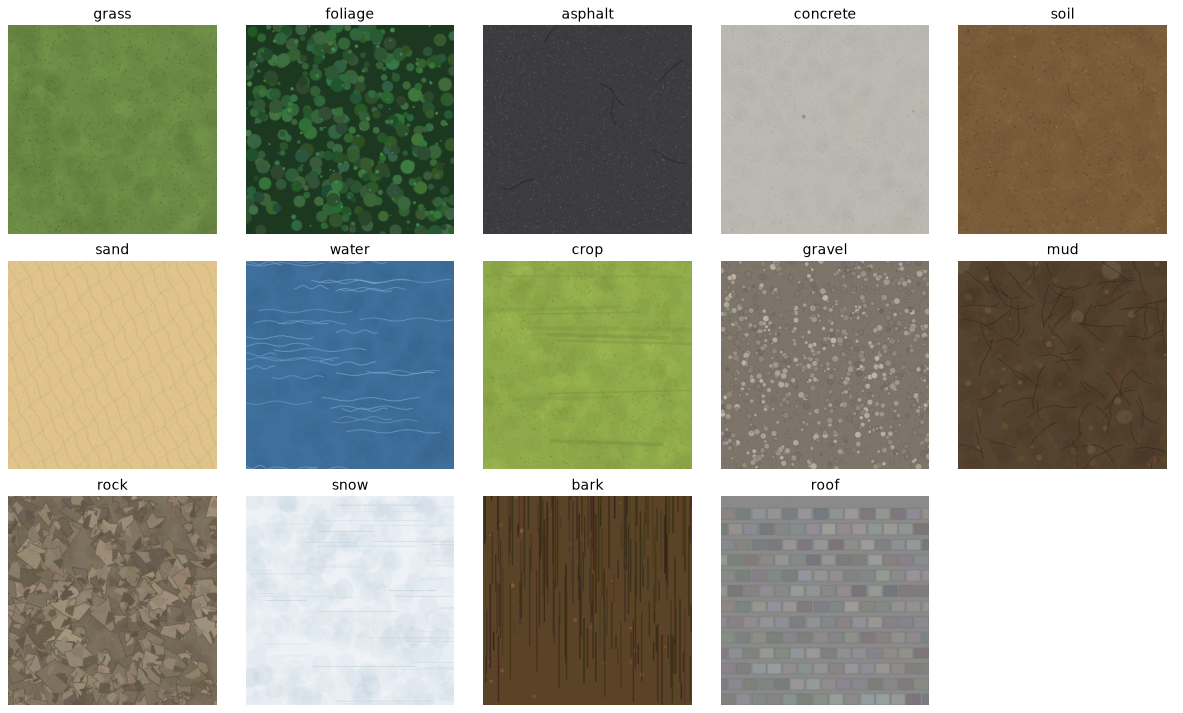

In [2]:
names = list(MATERIALS)
ncols = 5
nrows = (len(names) + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows), dpi=80)
for ax, name in zip(axes.ravel(), names, strict=False):
    ax.imshow(MATERIALS[name](size=300, seed=0))
    ax.set_title(name, fontsize=13)
    ax.axis("off")
for ax in axes.ravel()[len(names):]:
    ax.axis("off")
plt.tight_layout()
check_figure_size(fig)
plt.show()

### Visual analysis — gallery

A single seed-0 sample of each material:

- `grass`, `foliage`, `soil`, `water`, `crop`, `bark`, `concrete`, `roof` read
  as their intended surfaces and have plausible grain.
- `sand` shows clean parallel ripples in this sample (coverage problems appear
  on other seeds — see the 5-seed grid below).
- `rock` now reads as a rocky face of overlapping angular slabs in muted
  brown/grey with lit and shaded facets.
- `snow` has soft blue-grey relief undulations (improved in Round 4).
- `asphalt` cracks are short, bent lines rather than edge-long scratches.
- `gravel` reads as loose stones on a grey-brown base; `mud` as wet
  dark soil with cracks and puddle patches.

## Coverage: 5 seeds per material

Each material is rendered with five different seeds to check that the
randomness produces varied but still plausible surfaces.

figure: 0.14 MB
figure: 0.18 MB


figure: 0.21 MB


figure: 0.06 MB


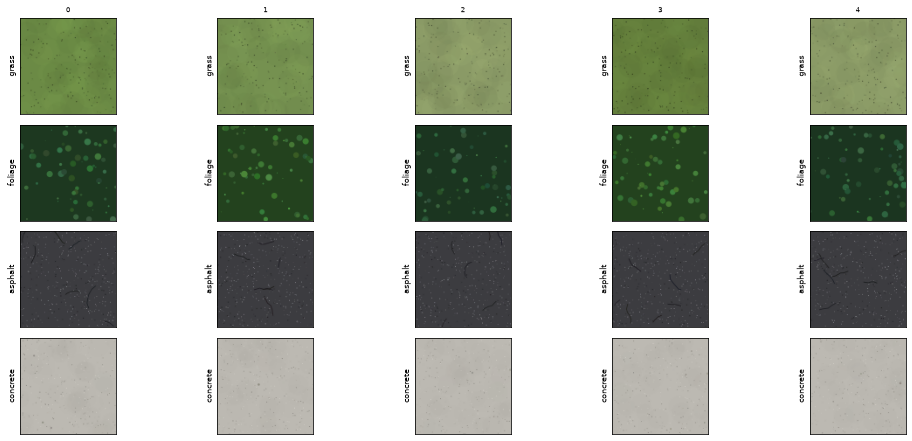

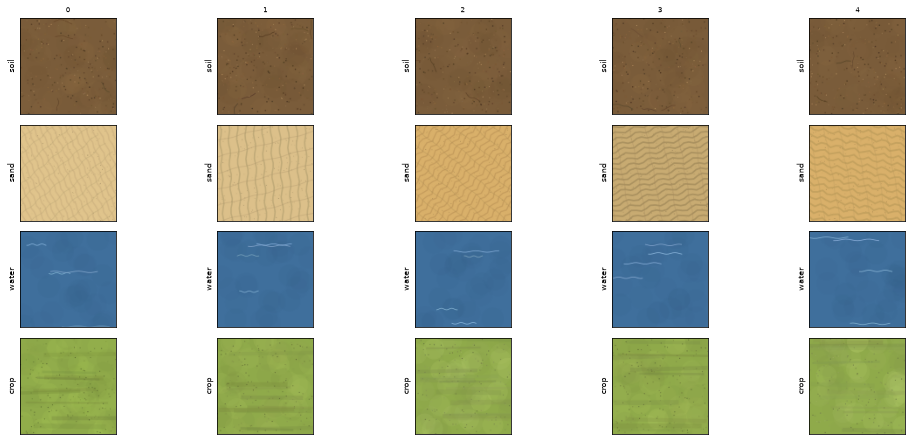

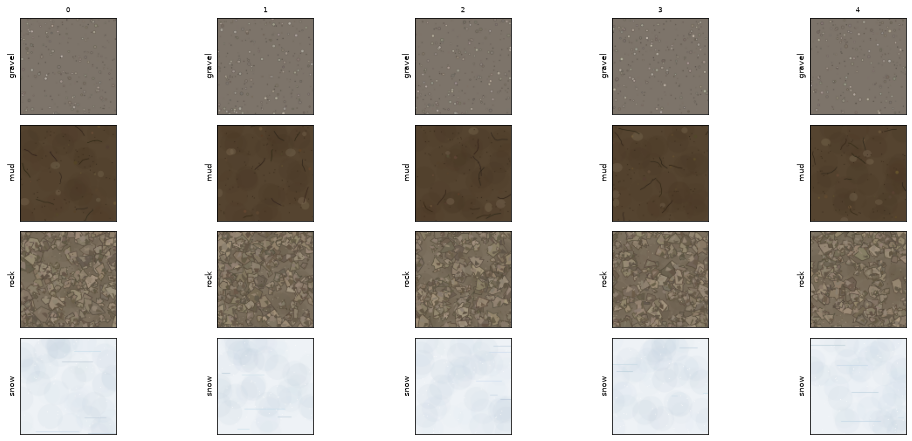

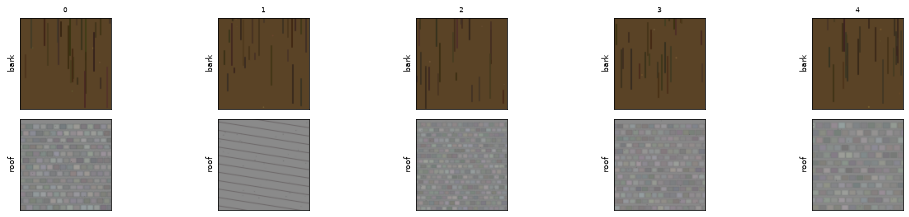

In [3]:
seeds = list(range(5))  # five instances per material

for group in [names[i:i + 4] for i in range(0, len(names), 4)]:
    fig, axes = plt.subplots(len(group), len(seeds), figsize=(15, 1.6 * len(group)), dpi=70)
    axes = np.atleast_2d(axes)
    for row, name in enumerate(group):
        for col, seed in enumerate(seeds):
            axes[row, col].imshow(MATERIALS[name](size=110, seed=seed))
            axes[row, col].set_ylabel(name, fontsize=8)
            if row == 0:
                axes[row, col].set_title(f"{seed}", fontsize=7)
            axes[row, col].set_xticks([])
            axes[row, col].set_yticks([])
    plt.tight_layout()
    check_figure_size(fig)
plt.show()

### Visual analysis — 5 seeds per material

- **grass / foliage / soil / water / crop / concrete / bark / roof** — stable and
  plausible across all five seeds; concrete joints and roof shingle/seam styles
  vary nicely, bark striations and water specular dashes differ per seed.
- **sand** — ripples now cover the whole tile at every seed (fixed in Round 4).
- **rock** — reads as overlapping grey/brown slabs with faceted shading across
  all five seeds (rebuilt in Round 4).
- **snow** — soft blue-grey relief undulations plus sparse specular dashes;
  varies per seed (improved in Round 4).
- **asphalt** — cracks are now short, bent random-walk lines (fixed in Round 4).
- **gravel** — small rounded stones on a grey-brown base; consistent,
  slightly sparse.
- **mud** — dark wet soil with bent cracks and pale puddle patches;
  a few faint coloured specks remain (low).

## Materials are reused as fills

`fill_patch` paints a material onto any shape, clipped to its geometry. The
same material field is shared by every shape that uses it, which is how
objects and grounds get a consistent grain.

shapes used: 4
figure: 0.05 MB


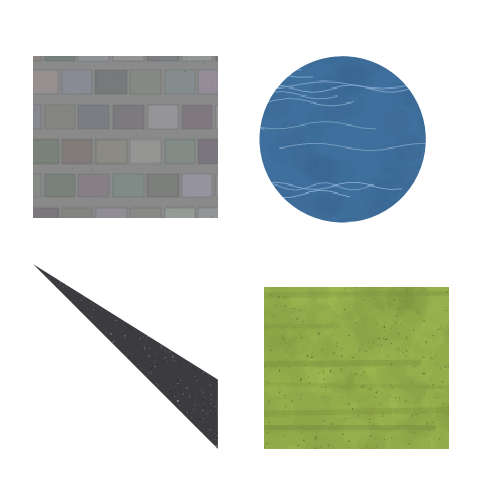

In [4]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_axis_off()
budget = ShapeBudget()

for texture_name, shape in [
    ("roof", patches.Rectangle((0.05, 0.55), 0.4, 0.35)),
    ("water", patches.Circle((0.72, 0.72), 0.18)),
    ("asphalt", patches.Polygon([[0.05, 0.45], [0.45, 0.2], [0.45, 0.05]])),
    ("crop", patches.Rectangle((0.55, 0.05), 0.4, 0.35)),
]:
    fill_patch(ax, shape, MATERIALS[texture_name](size=400, seed=0), budget=budget)
print("shapes used:", budget.count)
check_figure_size(fig)
plt.show()

### Visual analysis — material fills

`fill_patch` clips a material to a rectangle (`roof`), circle (`water`),
triangle (`asphalt`) and rectangle (`crop`). Clipping is correct for these
unrotated shapes and the shared texture field is consistent: the triangle shows
the asphalt grain and the circle shows the water material with specular dashes.

## Determinism

Same seed, same material.

In [5]:
a = generate_material("asphalt", size=128, seed=42)
b = generate_material("asphalt", size=128, seed=42)
print("same seed identical:", (a == b).all())
print("different seed differs:", not (a == generate_material("asphalt", size=128, seed=43)).all())

same seed identical: True
different seed differs: True
